In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [31]:
n = 100

heads = 58

p0 = 0.5

# Binomial PMF for every possible number of heads

k = np.arange(n + 1)


log_pmf = (np.array([sum(np.log(np.arange(1, n + 1)))
              - sum(np.log(np.arange(1, i + 1)))
              - sum(np.log(np.arange(1, n - i + 1))) for i in k])
    + k * np.log(p0)
    + (n - k) * np.log(1 - p0))

pmf = np.exp(log_pmf)

# Exact two-sided p-value

p_observed = pmf[heads]

p_value = 2 * pmf[heads:].sum()
# p_value = pmf[pmf <= p_observed * (1 + 1e-12)].sum()


print(f"Observed probability: {p_observed:.6f}")

print(f"Two-sided p-value: {p_value:.6f}")

Observed probability: 0.022292
Two-sided p-value: 0.133211


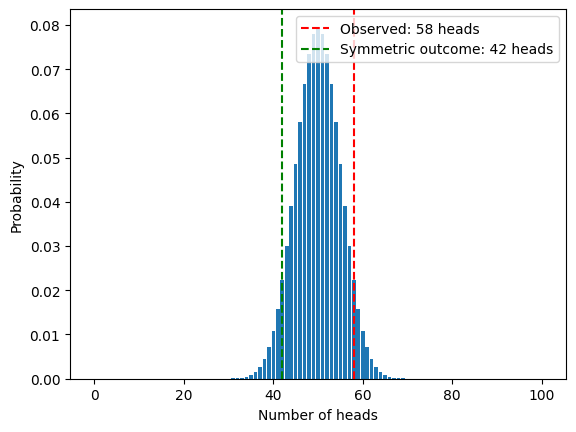

In [30]:
plt.bar(k, pmf)

plt.axvline(heads, linestyle="--", color="red",

            label=f"Observed: {heads} heads")

plt.axvline(n - heads, linestyle="--", color="green",

            label=f"Symmetric outcome: {n - heads} heads")

plt.xlabel("Number of heads")

plt.ylabel("Probability")

plt.legend()

In [ ]:
n = 100

heads = 58

p0 = 0.5


p_hat = heads / n

# Exact two-sided binomial test

result = stats.binomtest(heads, n, p=p0, alternative="two-sided")

p_value = result.pvalue

# 95% confidence interval

se = np.sqrt(p_hat * (1 - p_hat) / n)

ci_low = p_hat - 1.96 * se

ci_high = p_hat + 1.96 * se

print(f"Observed proportion: {p_hat:.3f}")

print(f"Binomial p-value: {p_value:.4f}")

print(f"95% confidence interval: [{ci_low:.3f}, {ci_high:.3f}]")

Observed proportion: 0.580
Exact binomial p-value: 0.1332
95% confidence interval: [0.483, 0.677]


In [26]:
np.random.seed(42)

n = 100

p_true = 0.5

n_experiments = 10000

# Simulate the number of heads in each experiment

heads = np.random.binomial(n, p_true, size=n_experiments)

p_hat = heads / n



se = np.sqrt(p_hat * (1 - p_hat) / n)

ci_low = p_hat - 1.96 * se

ci_high = p_hat + 1.96 * se

# Does each interval contain the true probability?

contains_true_p = (ci_low <= p_true) & (p_true <= ci_high)

print(f"Intervals containing true p: {contains_true_p.sum()}")

print(f"Total intervals: {n_experiments}")

print(f"Coverage: {contains_true_p.mean():.1%}")

Intervals containing true p: 9426
Total intervals: 10000
Coverage: 94.3%
